# 비교군 (Baseline) : Rehandle 을 처리시간에 포함한 Predetermined Twin-Crane 모델

`compare.ipynb` 를 수정. **반대편 크레인의 도움이 없는 현재 운영** 을 표현한다.

- 작업 인스턴스는 `Reha_Crane_predetermined.ipynb` 와 **동일** (`Seq_SC`, `Seq_LC` 셀을 똑같이 맞춰야 함)
- 순서 고정, 할당 고정 (DS·LD → SC, GI·GO → LC)
- Rehandle 은 독립 작업이 아니라 LD·GO 의 **처리시간에 포함**
- 남는 결정 : 크레인 간 간섭 순서 $z$, 시작시각 $s$

**검증** : 같은 인스턴스·같은 `OBJ` 에서 협업 모델의 `ALLOW_ASSIST=False, HOME_RH_FIXED=True` 결과와 같은 값이 나와야 한다
(toy, `OBJ="truck_wait"`: makespan 189, Σ 트럭 대기 1074, GO 만 541). `OBJ="makespan"` 에서는 makespan 이 같은 해가 여럿이라 트럭 대기 값은 다를 수 있다.

**변경 이력**
- 2026-10-01 · 순서·할당 고정, rehandle 할당 $x_{rv}$, 해측/육측 TP, `ALLOW_ASSIST` · `HOME_RH_FIXED` 옵션
- 2026-10-01 · 트럭 대기를 GO 만이 아니라 모든 트럭(DS·LD·GI·GO)으로 확장, `OBJ="truck_wait"` 추가
- 2026-10-06 · 시각화 셀: t̂·pick·drop 이 소수여도(실데이터 초 단위, t̂=1.5) 그려지도록 시간 반올림 · 이동 속도 1/t̂ 반영 (모델 변경 없음)
- 2026-10-13 · 협업 노트북에 `RH_AFTER_ARRIVAL` 추가. 비교군은 rehandle 이 본 작업 처리시간 안에 있어 원래 트럭 도착 뒤에만 수행 → 협업 `RH_AFTER_ARRIVAL=True` 와 같은 조건 (모델 변경 없음)
- 2026-10-28 · 협업 노트북에 `LD_LOOKAHEAD`(적하 rehandle 을 AGV 도착 전에 미리) 추가. 비교군은 rehandle 이 본 작업 안이라 미리 할 수 없음 — 현재 운영 방식 그대로 (모델 변경 없음)
- 2026-10-28 · `CRANE_READY` (크레인이 비는 시각) 추가 — 롤링 호라이즌용, 기본 0 = 예전과 같음 (협업 노트북과 같은 변경)



### Data (Predetermined Sequence) — 수정본 모델과 동일하게 유지

In [1]:
# =========================================================
# 1. 블록 / 크레인 / 작업 데이터 입력
# =========================================================
# Bay 좌표: 0 = 해측 TP(Sea TP), 1~N_BAY = 야드 Bay, N_BAY+1 = 육측 TP(Land TP)
N_BAY   = 30
SEA_TP  = 0
LAND_TP = N_BAY + 1
Bay = list(range(SEA_TP, LAND_TP + 1))

# SC = Seaside crane(해측, 홀수호기), LC = Landside crane(육측, 짝수호기)
Crane = {
    "SC": {"initial": SEA_TP},
    "LC": {"initial": LAND_TP},
}

# 작업 타입 -> 담당 크레인 (non-crossing 때문에 자동 결정)
TYPE_CRANE = {"DS": "SC", "LD": "SC", "GI": "LC", "GO": "LC"}

# ---------------------------------------------------------
# Predetermined Sequence
#   크레인별로 아래 dict 에 "적힌 순서" 가 곧 고정된 작업 순서
#   bay  : 야드 내 작업 Bay
#   r_c  : Rehandle 개수 (LD, GO 만 해당)
#   rh_d : (선택) Rehandle 별 목적 Bay 리스트. 없으면 제자리(같은 Bay) rehandle
#   a    : (선택) 작업 가능 시각 (GO = 트럭 도착 시각 등). 없으면 0
# ---------------------------------------------------------
Seq_SC = {
    "DS_1": {"type": "DS", "bay": 20},
    "LD_1": {"type": "LD", "bay": 8,  "r_c": 1},
    "DS_2": {"type": "DS", "bay": 10},
    "LD_2": {"type": "LD", "bay": 15, "r_c": 2, "rh_d": [15, 13]},
    "DS_3": {"type": "DS", "bay": 6},
}

Seq_LC = {
    "GO_1": {"type": "GO", "bay": 14, "r_c": 3, "a": 0},
    "GI_1": {"type": "GI", "bay": 22},
    "GO_2": {"type": "GO", "bay": 16, "r_c": 3, "rh_d": [16, 16, 19], "a": 10},
    "GO_3": {"type": "GO", "bay": 12, "r_c": 2, "a": 20},
    "GI_2": {"type": "GI", "bay": 26},
    "GO_4": {"type": "GO", "bay": 18, "r_c": 2, "a": 30},
    "GO_5": {"type": "GO", "bay": 25, "r_c": 0, "a": 40},
}

Sequence = {"SC": list(Seq_SC.keys()), "LC": list(Seq_LC.keys())}
Main_Jobs = {**Seq_SC, **Seq_LC}

# 타입과 크레인이 맞는지 확인
for v, seq in Sequence.items():
    for j in seq:
        assert TYPE_CRANE[Main_Jobs[j]["type"]] == v, f"{j} 는 {v} 의 작업이 아님"

### Tasks (rehandle 은 본 작업의 속성)

In [2]:
# =========================================================
# 2. Tasks 생성 (비교군: rehandle 을 독립 작업으로 만들지 않음)
# =========================================================
#   rehandle 은 본 작업(LD, GO)의 속성으로만 저장하고,
#   처리시간에 "rehandle 수행 시간 + rehandle 후 본 작업 Bay 로 돌아오는 이동" 을 더한다.
def od_of(job):
    t, b = job["type"], job["bay"]
    if t == "DS": return SEA_TP, b
    if t == "LD": return b, SEA_TP
    if t == "GI": return LAND_TP, b
    if t == "GO": return b, LAND_TP
    raise ValueError(t)

Tasks = {}
home = {}
for v, seq in Sequence.items():
    for j in seq:
        job = Main_Jobs[j]
        o, d = od_of(job)
        rc = job.get("r_c", 0)
        rh_d = job.get("rh_d", [job["bay"]] * rc)
        assert len(rh_d) == rc, f"{j}: rh_d 길이가 r_c 와 다름"
        Tasks[j] = {"o": o, "d": d, "a": job.get("a", 0), "type": job["type"],
                    "bay": job["bay"], "r_c": rc, "rh_d": rh_d}
        home[j] = v

Set_M = list(Tasks.keys())
print("[Tasks]")
for k, t in Tasks.items():
    print(f"  {k:<5} {home[k]}  o={t['o']:>2} d={t['d']:>2}  r_c={t['r_c']}  rh_d={t['rh_d']}")

[Tasks]
  DS_1  SC  o= 0 d=20  r_c=0  rh_d=[]
  LD_1  SC  o= 8 d= 0  r_c=1  rh_d=[8]
  DS_2  SC  o= 0 d=10  r_c=0  rh_d=[]
  LD_2  SC  o=15 d= 0  r_c=2  rh_d=[15, 13]
  DS_3  SC  o= 0 d= 6  r_c=0  rh_d=[]
  GO_1  LC  o=14 d=31  r_c=3  rh_d=[14, 14, 14]
  GI_1  LC  o=31 d=22  r_c=0  rh_d=[]
  GO_2  LC  o=16 d=31  r_c=3  rh_d=[16, 16, 19]
  GO_3  LC  o=12 d=31  r_c=2  rh_d=[12, 12]
  GI_2  LC  o=31 d=26  r_c=0  rh_d=[]
  GO_4  LC  o=18 d=31  r_c=2  rh_d=[18, 18]
  GO_5  LC  o=25 d=31  r_c=0  rh_d=[]


### Parameter

In [3]:
# =========================================================
# 3. Parameter
# =========================================================
safety_margin = 1
t_hat = 1
pick = 1
drop = 1
Lambda = pick
h = pick + drop
rh_inplace = 3        # 같은 Bay 안에서 옮기는 rehandle 1개 처리시간 (수정본 모델과 동일 값)

OBJ = "makespan"      # "makespan" / "truck_wait" / "go_wait"  (협업 모델과 같은 옵션)

# rehandle 1개의 처리시간 (수정본 모델의 rehandle 작업 duration 과 동일하게 계산)
def rh_proc(bay, dest):
    return rh_inplace if dest == bay else abs(bay - dest) * t_hat + h

# 본 작업 처리시간 = 본 작업 이동/상하역 + Σ_k ( rehandle k 처리시간 + 내려놓은 곳에서 본 작업 Bay 로 복귀 )
#   - 제자리 rehandle 만 있으면 = 기존 compare.ipynb 의  r_c * rehandle_time 과 동일
#   - 수정본 모델에서 ALLOW_ASSIST=False, HOME_RH_FIXED=True 일 때 원래 크레인이 하는 일과 같은 시간
rehandle_time = {}
duration = {}
for i, td in Tasks.items():
    rh = sum(rh_proc(td["bay"], dk) + abs(dk - td["bay"]) * t_hat for dk in td["rh_d"])
    rehandle_time[i] = rh
    duration[i] = abs(td["o"] - td["d"]) * t_hat + h + rh

travel_jobs = {(i, j): abs(Tasks[i]["d"] - Tasks[j]["o"]) * t_hat
               for i in Tasks for j in Tasks if i != j}

CRANE_READY = {"SC": 0, "LC": 0}   # 크레인이 비는 시각 (롤링 호라이즌: 하던 작업이 끝나는 시각). 보통 0
crane_initial = {v: Crane[v]["initial"] for v in Crane}
initial_CM = {(v, i): CRANE_READY.get(v, 0) + abs(crane_initial[v] - Tasks[i]["o"]) * t_hat for i in Tasks for v in Crane}

sort_crane = sorted(crane_initial.items(), key=lambda x: x[1])
crane_index = {k[0]: idx for idx, k in enumerate(sort_crane, start=1)}
delta = {(v, w): (safety_margin + 1) * abs(crane_index[v] - crane_index[w]) for v in Crane for w in Crane}

horizon = (sum(duration.values()) + max(Tasks[i]["a"] for i in Tasks) + max(CRANE_READY.values())
           + len(Tasks) * (LAND_TP - SEA_TP) * t_hat)
a = {i: Tasks[i]["a"] for i in Tasks}   # GO: 트럭 도착 이후에 rehandle + 반출 시작 (현재 운영 방식)
b = {i: horizon for i in Tasks}
BigM = horizon

print("[Duration (rehandle 포함)]")
for i in Tasks:
    print(f"  {i:<5} total={duration[i]:>3}  (rehandle {rehandle_time[i]})")
print("horizon / BigM =", horizon)

[Duration (rehandle 포함)]
  DS_1  total= 22  (rehandle 0)
  LD_1  total= 13  (rehandle 3)
  DS_2  total= 12  (rehandle 0)
  LD_2  total= 26  (rehandle 9)
  DS_3  total=  8  (rehandle 0)
  GO_1  total= 28  (rehandle 9)
  GI_1  total= 11  (rehandle 0)
  GO_2  total= 31  (rehandle 14)
  GO_3  total= 27  (rehandle 6)
  GI_2  total=  7  (rehandle 0)
  GO_4  total= 21  (rehandle 6)
  GO_5  total=  8  (rehandle 0)
horizon / BigM = 626


### Set

In [4]:
# =========================================================
# 4. Set
# =========================================================
Set_T = list(Tasks.keys())
Set_V = list(Crane.keys())

# 같은 크레인의 연속 작업 쌍 (순서 고정)
Fixed_Seq_Pairs = [(seq[k], seq[k + 1], v) for v, seq in Sequence.items() for k in range(len(seq) - 1)]

# 작업 구간 : rehandle 로 옮겨놓는 Bay 까지 포함
task_interval = {}
for t, d in Tasks.items():
    pts = [d["o"], d["d"]] + list(d["rh_d"])
    task_interval[t] = {"l_min": min(pts), "l_max": max(pts)}

# 충돌 잠재쌍 : 할당이 고정이므로 (i 의 크레인, j 의 크레인) 조합 하나만 검사
Theta = []
for t in Set_T:
    for tp in Set_T:
        if t == tp:
            continue
        v, w = home[t], home[tp]
        if v == w:
            continue
        if crane_index[v] < crane_index[w]:
            if task_interval[t]["l_max"] + delta[v, w] > task_interval[tp]["l_min"]:
                Theta.append((t, tp, v, w))
        else:
            if task_interval[t]["l_min"] - delta[v, w] < task_interval[tp]["l_max"]:
                Theta.append((t, tp, v, w))

print("Fixed sequence pairs :", len(Fixed_Seq_Pairs))
print("Theta :", len(Theta))

Fixed sequence pairs : 10
Theta : 14


### ETD (Extend Temporal Distance)

In [5]:
# =========================================================
# 5. ETD (Extend Temporal Distance) - 원본과 동일
# =========================================================
def compute_etd_paper(t, tp, v, w, Tasks, delta, crane_index, t_hat, Lambda):
    l1_t  = Tasks[t]["o"]
    l2_t  = Tasks[t]["d"]
    l1_tp = Tasks[tp]["o"]
    l2_tp = Tasks[tp]["d"]
    d = delta[(v, w)]
    if crane_index[v] < crane_index[w]:
        base = (l2_t + d - l1_tp) * t_hat
        C11 = (l2_t + d > l1_tp)
        C12 = (l1_t + d > l1_tp)
        C13 = (l2_t + d > l2_tp)
        if C11:
            return base, "Case1-C1.1"
        elif C12 or C13:
            return base - Lambda, "Case1-C1.2/C1.3"
        else:
            return base - 2 * Lambda, "Case1-otherwise"
    elif crane_index[v] > crane_index[w]:
        base = (l1_tp - l2_t + d) * t_hat
        C21 = (l2_t - d < l1_tp)
        C22 = (l1_t - d < l1_tp)
        C23 = (l2_t - d < l2_tp)
        if C21:
            return base, "Case2-C2.1"
        elif C22 or C23:
            return base - Lambda, "Case2-C2.2/C2.3"
        else:
            return base - 2 * Lambda, "Case2-otherwise"
    else:
        raise ValueError("동일한 크레인은 허용되지 않음")

ETD = {}
for t, tp, v, w in Theta:
    ETD[(t, tp, v, w)], _ = compute_etd_paper(t, tp, v, w, Tasks, delta, crane_index, t_hat, Lambda)

### Decision Variables

In [6]:
# =========================================================
# 6. Decision Variables
# =========================================================
#   할당 x, 크레인 내 순서 y 는 없음 (모두 고정)
#   남는 결정 : 크레인 간 간섭 순서 z, 시작시각 s
import gurobipy as gp
from gurobipy import GRB

model = gp.Model("Baseline_RH_in_duration")

z_keys = sorted({(i, j) for (i, j, v, w) in Theta} | {(j, i) for (i, j, v, w) in Theta})
z = model.addVars(z_keys, vtype=GRB.BINARY, name="z_ij")
s = model.addVars(Set_T, vtype=GRB.CONTINUOUS, lb=0, name="s_i")
makespan = model.addVar(vtype=GRB.CONTINUOUS, name="makespan")

Set parameter Username
Set parameter LicenseID to value 2795050
Academic license - for non-commercial use only - expires 2027-03-20


### 수리모형

$$p_i = |o_i-d_i|\,\hat t + \eta + \sum_{k=1}^{n_i}\Bigl(p^{RH}_{ik} + |d^{RH}_{ik} - b^y_i|\,\hat t\Bigr),\qquad p^{RH}_{ik}=\begin{cases}\rho & d^{RH}_{ik}=b^y_i\\ |b^y_i-d^{RH}_{ik}|\hat t+\eta & \text{otherwise}\end{cases}$$

제자리 rehandle 만 있으면 $p_i = |o_i-d_i|\hat t + \eta + n_i\rho$ (기존 compare.ipynb 의 `r_c * rehandle_time`).

| 번호 | 제약 |
|---|---|
| 목적 | 아래 표 (`OBJ`) |
| (3) | $s_i \ge \tau^0_{h(i),i},\ \forall i\in M$ |
| (5) | $s_i+p_i+t_{ij}\le s_j,\ \forall (i,j)\in F$ |
| (8) | $z_{ij}+z_{ji}\ge 1,\ \forall (i,j,v,w)\in\Theta$ |
| (9) | $s_i+p_i+ETD_{ijvw}\le s_j+\mathcal M(1-z_{ij}),\ \forall (i,j,v,w)\in\Theta$ |
| (10) | $a_i\le s_i\le b_i,\ \forall i\in M$ |
| (13) | $C_{max}\ge s_i+p_i,\ \forall i\in M$ |

$\Theta$ 는 할당이 고정이므로 $(i,j,h(i),h(j))$, $h(i)\ne h(j)$ 조합만 검사하고, 작업 구간 $[l^{\min}_i,l^{\max}_i]$ 에 rehandle 목적 Bay 까지 포함한다.

**트럭 대기 정의** (모든 작업에 트럭이 있음: DS·LD 내부 트럭, GI·GO 외부 트럭)

$$\phi_j=\begin{cases} s_j+\lambda & j\in M^{DS}\cup M^{GI}\ \ (\text{크레인이 TP 에서 집는 순간 트럭 출발})\\ s_j+p_j & j\in M^{LD}\cup M^{GO}\ \ (\text{TP 에 내려놓는 순간 트럭 출발})\end{cases},\qquad W_j=\phi_j-a_j$$

**목적함수** (`OBJ`, 두 노트북 공통)

| OBJ | 목적함수 |
|---|---|
| `"makespan"` | $\min C_{max}$ |
| `"truck_wait"` | $\min \sum_{j\in M} W_j + 10^{-3}C_{max}$ (모든 트럭) |
| `"go_wait"` | $\min \sum_{j\in M^{GO}} W_j + 10^{-3}C_{max}$ (GO 트럭만, 비교용) |

$a_j$ 는 목적함수에서 상수라 최적해를 바꾸지 않고, 스케줄에는 시간창 제약 $a_j\le s_j$ 로만 영향을 준다 (트럭이 늦게 와서 크레인이 기다릴 때만 binding).

비교군에서는 rehandle 이 LD·GO 처리시간 안에 있으므로, 원래 크레인의 rehandle 은 트럭이 도착한 뒤에야 시작된다 ($s_j \ge a_j$).


In [7]:
# =========================================================
# 7. 수리모형 (비교군)
# =========================================================
# 트럭 대기시간 정의 (모든 작업에 트럭이 있음: DS·LD = 내부 트럭, GI·GO = 외부 트럭)
#   DS·GI : 트럭이 컨테이너를 가져옴 → 크레인이 TP 에서 집으면(시작 + pick) 트럭 출발
#   LD·GO : 트럭이 컨테이너를 받아감 → 크레인이 TP 에 내려놓으면(완료) 트럭 출발
#   트럭 대기 = 트럭 출발 시각 - 트럭 도착 시각 a_j
truck_jobs = list(Set_M)
def truck_out(j, val=False):
    st = s[j].X if val else s[j]
    return st + pick if Tasks[j]["type"] in ("DS", "GI") else st + duration[j]
go_jobs = [j for j in Set_M if Tasks[j]["type"] == "GO"]
if OBJ == "makespan":
    model.setObjective(makespan, GRB.MINIMIZE)
elif OBJ == "truck_wait":
    # 모든 트럭 대기 합 + makespan 소량 가중
    model.setObjective(gp.quicksum(truck_out(j) - a[j] for j in truck_jobs) + 1e-3 * makespan,
                       GRB.MINIMIZE)
elif OBJ == "go_wait":
    # GO 트럭만 (반출 트럭 대기 합)
    model.setObjective(gp.quicksum(truck_out(j) - a[j] for j in go_jobs) + 1e-3 * makespan,
                       GRB.MINIMIZE)
else:
    raise ValueError(f"OBJ 는 makespan / truck_wait / go_wait 중 하나: {OBJ}")

# (3) 초기 위치 -> 작업 시작점 이동 (크레인 고정)
for i in Set_T:
    model.addConstr(s[i] >= initial_CM[home[i], i], name=f"3_{i}")

# (5) Predetermined sequence
for (i, j, v) in Fixed_Seq_Pairs:
    model.addConstr(s[i] + duration[i] + travel_jobs[i, j] <= s[j], name=f"5_fix_{i}_{j}")

# (8) 크레인 간 간섭 순서 : 서로 다른 크레인이므로 항상 둘 중 하나가 먼저
for (i, j, v, w) in Theta:
    model.addConstr(z[i, j] + z[j, i] >= 1, name=f"8_{i}_{j}")

# (9) ETD
for (i, j, v, w) in Theta:
    model.addConstr(s[i] + duration[i] + ETD[i, j, v, w] <= s[j] + BigM * (1 - z[i, j]),
                    name=f"9_{i}_{j}")

# (10) 시간창
for i in Set_T:
    model.addConstr(a[i] <= s[i], name=f"10a_{i}")
    model.addConstr(s[i] <= b[i], name=f"10b_{i}")

# (13) makespan
for i in Set_T:
    model.addConstr(makespan >= s[i] + duration[i], name=f"13_{i}")

### Solve & Result

In [8]:
# =========================================================
# 8. Solve & Result
# =========================================================
model.Params.OutputFlag = 1
model.Params.TimeLimit = 300
model.optimize()

result_rows = []
if model.SolCount > 0:
    print("\n==============================")
    print("Optimization Result (Baseline : rehandle in duration)")
    print("==============================")
    status_txt = {GRB.OPTIMAL: "OPTIMAL", GRB.TIME_LIMIT: "TIME_LIMIT (현재까지 최선해)"}
    print("Status      :", status_txt.get(model.Status, f"Code {model.Status}"))
    print("OBJ         :", OBJ)

    for i in Set_T:
        result_rows.append({
            "task": i, "crane": home[i],
            "origin": Tasks[i]["o"], "destination": Tasks[i]["d"],
            "start": s[i].X, "duration": duration[i],
            "rehandle": rehandle_time[i],
            "completion": s[i].X + duration[i],
        })
    result_rows = sorted(result_rows, key=lambda r: r["start"])

    truck_wait = {j: truck_out(j, val=True) - a[j] for j in truck_jobs}
    by_type = {}
    for j, w in truck_wait.items():
        by_type.setdefault(Tasks[j]["type"], []).append(w)
    print(f"Makespan              = {makespan.X:.2f}")
    print(f"Σ 트럭 대기 (전체)      = {sum(truck_wait.values()):.2f}")
    for t in ("DS", "LD", "GI", "GO"):
        if t in by_type:
            print(f"   {t} 트럭 {len(by_type[t]):>2}대 : 합 {sum(by_type[t]):8.2f} / 평균 {sum(by_type[t]) / len(by_type[t]):6.2f}")
    print(f"지원받은 Rehandle 수    = 0 / {sum(Tasks[i]['r_c'] for i in Set_T)}  (비교군)")

    print("\n[Crane-wise Sequence]")
    for v in Set_V:
        print(f"\nCrane {v}")
        for idx, row in enumerate([r for r in result_rows if r["crane"] == v], start=1):
            rh = f"  (rehandle {row['rehandle']} 포함)" if row["rehandle"] > 0 else ""
            print(f"  {idx:>2}. {row['task']:<5} start={row['start']:7.2f} end={row['completion']:7.2f} "
                  f"o={row['origin']:>2} -> d={row['destination']:>2}{rh}")
else:
    print("Feasible solution 없음. Status =", model.Status)

Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (mac64[arm] - Darwin 25.6.0 25G83)

CPU model: Apple M3
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Non-default parameters:
TimeLimit  300

Optimize a model with 86 rows, 27 columns and 150 nonzeros (Min)
Model fingerprint: 0xac3518e1
Model has 1 linear objective coefficients
Variable types: 13 continuous, 14 integer (14 binary)
Coefficient statistics:
  Matrix range     [1e+00, 6e+02]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 6e+02]

Found heuristic solution: objective 202.0000000
Presolve removed 68 rows and 17 columns
Presolve time: 0.01s
Presolved: 18 rows, 10 columns, 44 nonzeros
Variable types: 6 continuous, 4 integer (4 binary)

Root relaxation: objective 1.890000e+02, 3 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds     

### Visualization

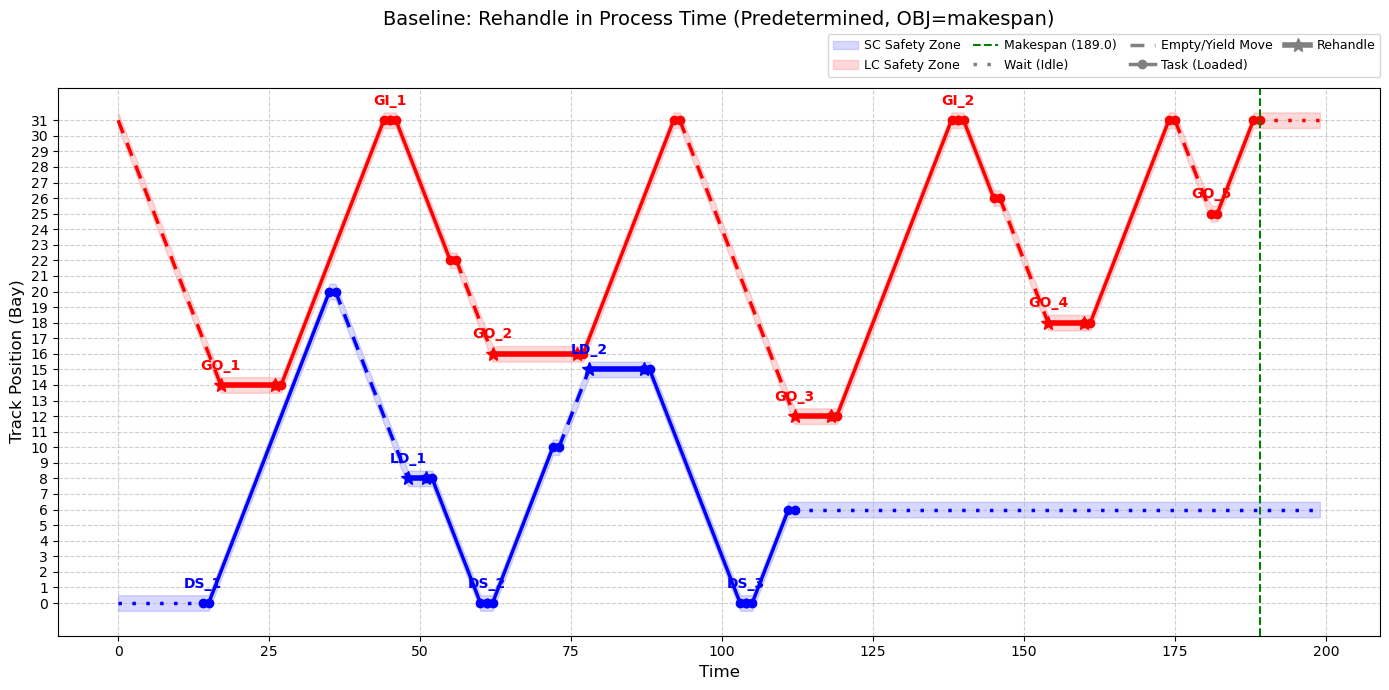

In [9]:
# =========================================================
# 9. Visualization (compare.ipynb 시각화 재사용)
#    굵은 선 + * = 본 작업 시작 전에 포함된 rehandle 시간
# =========================================================
if model.SolCount > 0:
    import math
    import matplotlib.pyplot as plt
    import matplotlib.lines as mlines

    # =========================
    # Visualization
    # =========================
    plt.figure(figsize=(14, 7))
    crane_colors = {"SC": "blue", "LC": "red"}

    # 시간축은 정수 격자(1 단위). t_hat·pick·drop 이 소수(실데이터 초 단위 등)여도 되도록 반올림하고,
    # 빈 이동 속도는 1/t_hat bay per 시간 단위로 그린다.
    _r = lambda x: int(round(x))
    _pick = _r(pick)
    _vmax = 1.0 / t_hat
    max_t = int(math.ceil(makespan.X)) + 10
    time_arr = list(range(max_t + 1))
    ypos = {v: [float(crane_initial[v])] * (max_t + 1) for v in Set_V}
    state = {v: ['idle'] * (max_t + 1) for v in Set_V}

    sorted_cranes = sorted(Set_V, key=lambda v: crane_index[v])
    c_bottom = sorted_cranes[0]  
    c_top = sorted_cranes[1]     
    delta_val = delta[(c_bottom, c_top)]

    for v in Set_V:
        tasks = [r for r in result_rows if r["crane"] == v]
        for task in tasks:
            start_t = int(round(task["start"]))
            dur = int(round(task["duration"]))
            o_loc = task["origin"]
            d_loc = task["destination"]
            
            travel_time = _r(abs(o_loc - d_loc) * t_hat)
            rehandle_dur = _r(dur - (pick + drop + abs(o_loc - d_loc) * t_hat))
            
            curr_time = start_t
            
            if rehandle_dur > 0:
                for t in range(curr_time, curr_time + rehandle_dur):
                    if t <= max_t:
                        ypos[v][t] = float(o_loc)
                        state[v][t] = 'active'
                curr_time += rehandle_dur
                
            for t in range(curr_time, curr_time + _pick):
                if t <= max_t:
                    ypos[v][t] = float(o_loc)
                    state[v][t] = 'active'
            curr_time += _pick
            
            arr_time = curr_time + travel_time
            step = (d_loc - o_loc) / travel_time if travel_time > 0 else 0.0
            curr_y = float(o_loc)
            for t in range(curr_time, arr_time + 1):
                if t <= max_t:
                    ypos[v][t] = curr_y
                    state[v][t] = 'active'
                if t < arr_time: curr_y += step
            curr_time = arr_time
            
            for t in range(curr_time, start_t + dur + 1):
                if t <= max_t:
                    ypos[v][t] = float(d_loc)
                    state[v][t] = 'active'

    for v in Set_V:
        tasks = [r for r in result_rows if r["crane"] == v]
        if not tasks: continue
        
        first_start = int(round(tasks[0]["start"]))
        loc_first = tasks[0]["origin"]
        dist_first = _r(abs(crane_initial[v] - loc_first) * t_hat)
        move_start_first = first_start - dist_first
        
        curr_y = float(crane_initial[v])
        step = (loc_first - crane_initial[v]) / dist_first if dist_first > 0 else 0.0
        for t in range(max(0, move_start_first), first_start):
            if t <= max_t and state[v][t] == 'idle':
                ypos[v][t] = curr_y
                curr_y += step
                
        for t in range(0, max(0, move_start_first)):
            if t <= max_t and state[v][t] == 'idle': ypos[v][t] = float(crane_initial[v])

        for i in range(len(tasks)-1):
            end_prev = int(round(tasks[i]["completion"]))
            start_next = int(round(tasks[i+1]["start"]))
            loc_prev = tasks[i]["destination"]
            loc_next = tasks[i+1]["origin"]
            dist = _r(abs(loc_prev - loc_next) * t_hat)
            move_start = start_next - dist
            
            for t in range(end_prev, move_start):
                if t <= max_t and state[v][t] == 'idle': ypos[v][t] = float(loc_prev)
            
            curr_y = float(loc_prev)
            step = (loc_next - loc_prev) / dist if dist > 0 else 0.0
            for t in range(max(end_prev, move_start), start_next):
                if t <= max_t and state[v][t] == 'idle':
                    ypos[v][t] = curr_y
                    curr_y += step

        last_end = int(round(tasks[-1]["completion"]))
        loc_last = tasks[-1]["destination"]
        for t in range(last_end, max_t + 1):
            if state[v][t] == 'idle': ypos[v][t] = float(loc_last)

    for sweep in range(300):
        for t in range(max_t + 1):
            if ypos[c_bottom][t] > ypos[c_top][t] - delta_val: 
                if state[c_bottom][t] == 'active' and state[c_top][t] == 'idle':
                    ypos[c_top][t] = ypos[c_bottom][t] + delta_val
                elif state[c_top][t] == 'active' and state[c_bottom][t] == 'idle':
                    ypos[c_bottom][t] = ypos[c_top][t] - delta_val
                elif state[c_bottom][t] == 'idle' and state[c_top][t] == 'idle':
                    mid = (ypos[c_bottom][t] + ypos[c_top][t]) / 2.0
                    ypos[c_bottom][t] = mid - delta_val / 2.0
                    ypos[c_top][t] = mid + delta_val / 2.0
        
        for v in Set_V:
            for t in range(1, max_t + 1):
                if state[v][t] == 'idle':
                    if ypos[v][t] > ypos[v][t-1] + _vmax: ypos[v][t] = ypos[v][t-1] + _vmax
                    if ypos[v][t] < ypos[v][t-1] - _vmax: ypos[v][t] = ypos[v][t-1] - _vmax
            for t in range(max_t - 1, -1, -1):
                if state[v][t] == 'idle':
                    if ypos[v][t] > ypos[v][t+1] + _vmax: ypos[v][t] = ypos[v][t+1] + _vmax
                    if ypos[v][t] < ypos[v][t+1] - _vmax: ypos[v][t] = ypos[v][t+1] - _vmax
        
        for v in Set_V:
            ypos[v][0] = float(crane_initial[v])

    for v in Set_V:
        upper_bounds = [val + 0.5 for val in ypos[v]]
        lower_bounds = [val - 0.5 for val in ypos[v]]
        plt.fill_between(
            time_arr, lower_bounds, upper_bounds,
            color=crane_colors[v],
            alpha=0.15,
            label=f'{v} Safety Zone'
        )

        tasks = [r for r in result_rows if r["crane"] == v]
        for task in tasks:
            start_t = task["start"]
            dur = task["duration"]
            o_loc = task["origin"]
            d_loc = task["destination"]
            
            travel_time = abs(o_loc - d_loc) * t_hat
            rehandle_dur = dur - (pick + drop + travel_time)
            
            curr_time = start_t
            
            if rehandle_dur > 0:
                rehandle_end = curr_time + rehandle_dur
                plt.plot([curr_time, rehandle_end], [o_loc, o_loc], color=crane_colors[v], linestyle='-', linewidth=4.0, marker='*', markersize=10)
                curr_time = rehandle_end
                
            pick_end = curr_time + pick
            plt.plot([curr_time, pick_end], [o_loc, o_loc], color=crane_colors[v], linestyle='-', linewidth=2.5, marker='o')
            
            arr_time = pick_end + travel_time
            plt.plot([pick_end, arr_time], [o_loc, d_loc], color=crane_colors[v], linestyle='-', linewidth=2.5)
            
            finish_time = arr_time + drop
            plt.plot([arr_time, finish_time], [d_loc, d_loc], color=crane_colors[v], linestyle='-', linewidth=2.5, marker='o')

            task_label = str(task["task"])
            plt.text(start_t, o_loc + 0.8, task_label, fontsize=10, color=crane_colors[v], fontweight='bold', ha='center', va='bottom')

        intervals = []
        for t in range(max_t):
            if state[v][t] == 'active' and state[v][t+1] == 'active':
                intervals.append('active')
            else:
                speed = abs(ypos[v][t+1] - ypos[v][t])
                intervals.append('empty' if speed > 0.01 else 'wait')

        start_t = 0
        while start_t < max_t:
            ctype = intervals[start_t]
            if ctype == 'active':
                start_t += 1
                continue
                
            end_t = start_t
            while end_t < max_t and intervals[end_t] == ctype:
                end_t += 1
                
            t_arr = list(range(start_t, end_t + 1))
            y_arr = [ypos[v][t] for t in t_arr]
            
            if ctype == 'empty':
                plt.plot(t_arr, y_arr, color=crane_colors[v], linestyle='--', dashes=(4, 3), linewidth=2.5)
            elif ctype == 'wait':
                plt.plot(t_arr, y_arr, color=crane_colors[v], linestyle=':', dashes=(1, 3), linewidth=2.5)
                
            start_t = end_t

    if makespan.X > 0:
        plt.axvline(x=makespan.X, color='green', linestyle='--', label=f'Makespan ({makespan.X:.1f})')

    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    
    wait_line = mlines.Line2D([], [], color='gray', linestyle=':', dashes=(1, 3), linewidth=2.5, label='Wait (Idle)')
    empty_line = mlines.Line2D([], [], color='gray', linestyle='--', dashes=(4, 3), linewidth=2.5, label='Empty/Yield Move')
    loaded_line = mlines.Line2D([], [], color='gray', linestyle='-', linewidth=2.5, marker='o', label='Task (Loaded)')
    rehandle_line = mlines.Line2D([], [], color='gray', linestyle='-', linewidth=4.0, marker='*', markersize=10, label='Rehandle')

    final_handles = list(by_label.values()) + [wait_line, empty_line, loaded_line, rehandle_line]
    final_labels = list(by_label.keys()) + ['Wait (Idle)', 'Empty/Yield Move', 'Task (Loaded)', 'Rehandle']

    plt.legend(final_handles, final_labels, loc='lower right', bbox_to_anchor=(1.0, 1.02), ncol=4, fontsize=9, columnspacing=1.0, handletextpad=0.5, borderaxespad=0.)
    plt.xlabel("Time", fontsize=12)
    plt.ylabel("Track Position (Bay)", fontsize=12)
    plt.title(f"Baseline: Rehandle in Process Time (Predetermined, OBJ={OBJ})", fontsize=14, pad=45)
    plt.yticks(Bay) 
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()